# Training a Markov GP — maximum likelihood, NUTS, variational inference, and what the data can tell you

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/pyrox/blob/main/docs/notebooks/ssm/markov_gp_training.ipynb)

`MarkovGPPrior.log_marginal(y, noise_var)` is the Kalman-filter marginal likelihood of a GP with a Gaussian likelihood. It is differentiable in every kernel hyperparameter through the SDE construction and the `lax.scan`-based filter, and it costs $\mathcal{O}(N\,d^3)$ per evaluation. That makes three ways of setting the hyperparameters $\boldsymbol{\theta} = (\sigma^2, \ell, \sigma_n^2)$ cheap:

1. **a point estimate**: maximise $\log p(\mathbf{y} \mid \boldsymbol{\theta})$ with L-BFGS (type-II maximum likelihood);
2. **the full posterior** $p(\boldsymbol{\theta} \mid \mathbf{y})$ with NUTS, through `markov_gp_factor` in a NumPyro model;
3. **an approximate posterior** with stochastic variational inference, mean-field and full-rank.

The last section asks what any of them can recover: which hyperparameters a record actually constrains, and how record length, sampling density and gaps change that, framed for geoscience time series.

## Setup

Detect Colab and install `pyrox-gp[colab]` (which pulls in `matplotlib` and `watermark`) and `pyrox-ssm` only when running there.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "pyrox @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox",
            "pyrox-gp[colab] @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-gp",
            "pyrox-ssm @ git+https://github.com/jejjohnson/pyrox@main#subdirectory=packages/pyrox-ssm",
        ],
        check=True,
    )

In [2]:
import warnings


warnings.filterwarnings("ignore", message=r".*IProgress.*")

import equinox as eqx
import jax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import numpyro
import numpyro.distributions as dist
import optax
from numpyro import handlers
from numpyro.infer import MCMC, NUTS, SVI, Trace_ELBO
from numpyro.infer.autoguide import AutoMultivariateNormal, AutoNormal
from pyrox_ssm import MarkovGPPrior, MaternSDE, markov_gp_factor


jax.config.update("jax_enable_x64", True)

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,numpyro,pyrox,matplotlib")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.13.0

jax       : 0.10.2
equinox   : 0.13.8
numpyro   : 0.21.0
pyrox     : 0.2.1
matplotlib: 3.10.9

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Synthetic data

A noisy mixture of two sinusoids on an irregular time grid of $N = 60$ points over $t \in [0, 8]$, fitted below with a Matern-3/2 SDE prior. The signal is not a draw from that prior, so no hyperparameter value is "true" here; section 4 uses data drawn from a known Matern-3/2 GP for that.

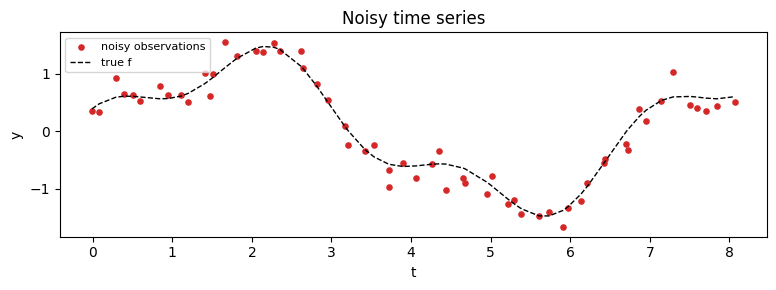

In [4]:
N = 60
t_clean = jnp.linspace(0.0, 8.0, N)
times = jnp.sort(t_clean + 0.05 * jax.random.normal(jax.random.PRNGKey(2), (N,)))
f_true = 1.2 * jnp.sin(0.9 * times) + 0.4 * jnp.cos(2.7 * times)
y = f_true + 0.18 * jax.random.normal(jax.random.PRNGKey(0), (N,))

fig, ax = plt.subplots(figsize=(8, 3))
ax.scatter(times, y, c="C3", s=14, label="noisy observations")
ax.plot(times, f_true, "k--", lw=1, label="true f")
ax.set_xlabel("t")
ax.set_ylabel("y")
ax.set_title("Noisy time series")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 2. A point estimate: type-II maximum likelihood with L-BFGS

We optimise in log-space so that $\sigma^2, \ell, \sigma_n^2 > 0$ holds automatically. The model lives in a small `equinox.Module` so it composes with `optax`.

In [5]:
class MarkovGPModel(eqx.Module):
    log_variance: jax.Array
    log_lengthscale: jax.Array
    log_noise_var: jax.Array
    times: jax.Array

    def __init__(self, times: jax.Array, init: tuple[float, float, float]) -> None:
        self.log_variance = jnp.asarray(jnp.log(init[0]))
        self.log_lengthscale = jnp.asarray(jnp.log(init[1]))
        self.log_noise_var = jnp.asarray(jnp.log(init[2]))
        self.times = times

    def neg_log_marginal(self, y: jax.Array) -> jax.Array:
        sde = MaternSDE(
            variance=jnp.exp(self.log_variance),
            lengthscale=jnp.exp(self.log_lengthscale),
            order=1,
        )
        prior = MarkovGPPrior(sde, self.times)
        return -prior.log_marginal(y, jnp.exp(self.log_noise_var))


model = MarkovGPModel(times, init=(0.5, 0.5, 0.1))
print(f"initial NLL: {float(model.neg_log_marginal(y)):.3f}")

initial NLL: 26.632


In [6]:
@eqx.filter_jit
def loss_and_grad(m: MarkovGPModel, y: jax.Array) -> tuple[jax.Array, MarkovGPModel]:
    return eqx.filter_value_and_grad(lambda mm: mm.neg_log_marginal(y))(m)


opt = optax.lbfgs()
params, static = eqx.partition(model, eqx.is_array)
opt_state = opt.init(params)


@eqx.filter_jit
def step(params, static, opt_state, y):
    m = eqx.combine(params, static)
    val, grads = loss_and_grad(m, y)
    grad_params, _ = eqx.partition(grads, eqx.is_array)
    updates, opt_state = opt.update(
        grad_params,
        opt_state,
        params,
        value=val,
        grad=grad_params,
        value_fn=lambda p: eqx.combine(p, static).neg_log_marginal(y),
    )
    params = optax.apply_updates(params, updates)
    return params, opt_state, val


losses = []
hyper_traces = {"variance": [], "lengthscale": [], "noise_var": []}
for it in range(40):
    params, opt_state, val = step(params, static, opt_state, y)
    losses.append(float(val))
    m_now = eqx.combine(params, static)
    hyper_traces["variance"].append(float(jnp.exp(m_now.log_variance)))
    hyper_traces["lengthscale"].append(float(jnp.exp(m_now.log_lengthscale)))
    hyper_traces["noise_var"].append(float(jnp.exp(m_now.log_noise_var)))

trained = eqx.combine(params, static)
print(f"final NLL: {losses[-1]:.3f}")
print(f"learned variance:    {hyper_traces['variance'][-1]:.3f}")
print(f"learned lengthscale: {hyper_traces['lengthscale'][-1]:.3f}")
print(f"learned noise_var:   {hyper_traces['noise_var'][-1]:.4f}")

final NLL: -20.833
learned variance:    0.417
learned lengthscale: 1.461
learned noise_var:   0.0237


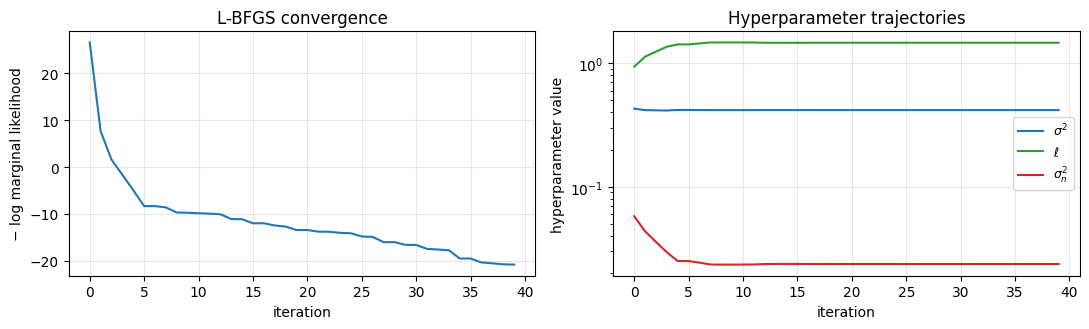

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(losses, "C0", lw=1.5)
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("− log marginal likelihood")
axes[0].set_title("L-BFGS convergence")
axes[0].grid(alpha=0.3)

axes[1].plot(hyper_traces["variance"], label=r"$\sigma^2$", color="C0")
axes[1].plot(hyper_traces["lengthscale"], label=r"$\ell$", color="C2")
axes[1].plot(hyper_traces["noise_var"], label=r"$\sigma_n^2$", color="C3")
axes[1].set_xlabel("iteration")
axes[1].set_ylabel("hyperparameter value")
axes[1].set_title("Hyperparameter trajectories")
axes[1].set_yscale("log")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

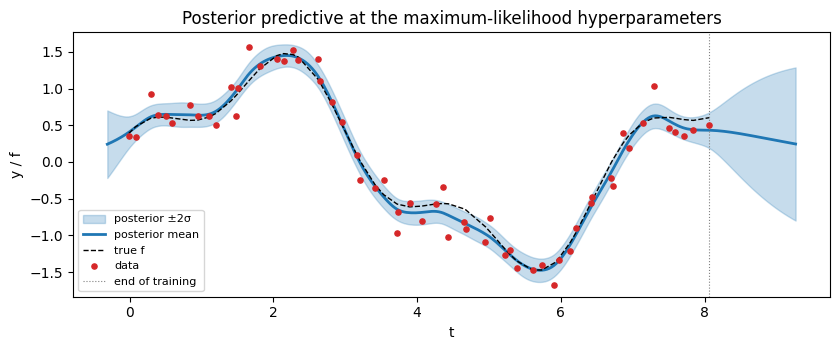

In [8]:
sde_final = MaternSDE(
    variance=jnp.exp(trained.log_variance),
    lengthscale=jnp.exp(trained.log_lengthscale),
    order=1,
)
prior_final = MarkovGPPrior(sde_final, times)
cond = prior_final.condition(y, jnp.exp(trained.log_noise_var))

t_star = jnp.linspace(times[0] - 0.3, times[-1] + 1.2, 300)
m_star, v_star = cond.predict(t_star)
m_star, v_star = np.asarray(m_star), np.asarray(v_star)
sd_star = np.sqrt(np.maximum(v_star, 0))

fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.fill_between(
    t_star,
    m_star - 2 * sd_star,
    m_star + 2 * sd_star,
    color="C0",
    alpha=0.25,
    label="posterior ±2σ",
)
ax.plot(t_star, m_star, color="C0", lw=2, label="posterior mean")
ax.plot(times, f_true, "k--", lw=1, label="true f")
ax.scatter(times, y, c="C3", s=14, label="data", zorder=3)
ax.axvline(times[-1], color="grey", ls=":", lw=0.8, label="end of training")
ax.set_xlabel("t")
ax.set_ylabel("y / f")
ax.set_title("Posterior predictive at the maximum-likelihood hyperparameters")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.show()

The point estimate gives a sensible fit, but it is one value of $\boldsymbol{\theta}$: the band above treats the hyperparameters as known. The next section puts priors on them and asks how uncertain they are.

## 3. Bayesian hyperparameters in NumPyro

### 3.1 The model

`markov_gp_factor` adds the Kalman marginal likelihood $\log p(\mathbf{y} \mid \boldsymbol{\theta})$ to a NumPyro model as a factor site, with the latent function integrated out. The model therefore has only three sample sites, one per hyperparameter, and every log-density evaluation is one $\mathcal{O}(N\,d^3)$ filter pass.

The priors encode what a record can and cannot inform:

- $\sigma^2 \sim \mathrm{LogNormal}(0, 1)$: weakly informative around the data's own scale.
- $\ell \sim \mathrm{InverseGamma}(3, 3)$: mean 1.5, with almost no mass below the sampling interval (about 0.13) or above the record length (8). A lengthscale below the sampling interval is indistinguishable from noise, and one beyond the record shows no decorrelation inside it, so the likelihood is flat in both directions; the prior keeps the posterior away from those regions. The inverse-gamma's light left tail is what does this.
- $\sigma_n^2 \sim \mathrm{LogNormal}(\log 0.05, 1)$.

In [9]:
def gp_model(times: jax.Array, y: jax.Array | None = None) -> None:
    variance = numpyro.sample("variance", dist.LogNormal(0.0, 1.0))
    lengthscale = numpyro.sample("lengthscale", dist.InverseGamma(3.0, 3.0))
    noise_var = numpyro.sample("noise_var", dist.LogNormal(jnp.log(0.05), 1.0))
    prior = MarkovGPPrior(
        MaternSDE(variance=variance, lengthscale=lengthscale, order=1), times
    )
    markov_gp_factor("y", prior, y, noise_var)


ell_prior = dist.InverseGamma(3.0, 3.0)
print(f"prior P(ell < 0.3) = {float(ell_prior.cdf(0.3)):.4f}")
print(f"prior P(ell > 8)   = {float(1 - ell_prior.cdf(8.0)):.4f}")

trace = handlers.trace(handlers.seed(gp_model, rng_seed=0)).get_trace(times, y)
for name, site in trace.items():
    print(f"site {name!r:14} type={site['type']}")

prior P(ell < 0.3) = 0.0028
prior P(ell > 8)   = 0.0067


site 'variance'     type=sample
site 'lengthscale'  type=sample
site 'noise_var'    type=sample
site 'y'            type=sample


### 3.2 MCMC with NUTS

NUTS (Hoffman & Gelman, 2014) is the right sampler here: three continuous parameters, a smooth log-density with exact gradients, and no latent function in the state because the factor has integrated it out, so there is no funnel between $\mathbf{f}$ and its hyperparameters to trap the sampler. Two chains of 1000 draws after 500 warm-up steps are plenty for three parameters.

In [10]:
mcmc = MCMC(
    NUTS(gp_model),
    num_warmup=500,
    num_samples=1000,
    num_chains=2,
    chain_method="sequential",
    progress_bar=False,
)
mcmc.run(jr.PRNGKey(1), times, y)
mcmc.print_summary()
nuts_samples = mcmc.get_samples()


                   mean       std    median      5.0%     95.0%     n_eff     r_hat
  lengthscale      1.46      0.40      1.39      0.84      2.06    851.06      1.00
    noise_var      0.04      0.01      0.03      0.02      0.05   1088.75      1.00
     variance      1.00      0.71      0.83      0.23      1.69    714.88      1.00

Number of divergences: 0


Both chains agree ($\hat R = 1.00$), the effective sample sizes are in the hundreds, and there are no divergences.

### 3.3 Stochastic variational inference: mean-field and full-rank

SVI fits a Gaussian $q(\boldsymbol{\theta}; \boldsymbol{\nu})$ in the unconstrained (log) space by maximising the ELBO. With three parameters the choice of guide is easy: `AutoMultivariateNormal` learns a full $3 \times 3$ covariance at negligible cost, which matters because the posterior is correlated; `AutoNormal` (mean-field) is shown for contrast, because it is the default people reach for on larger models.

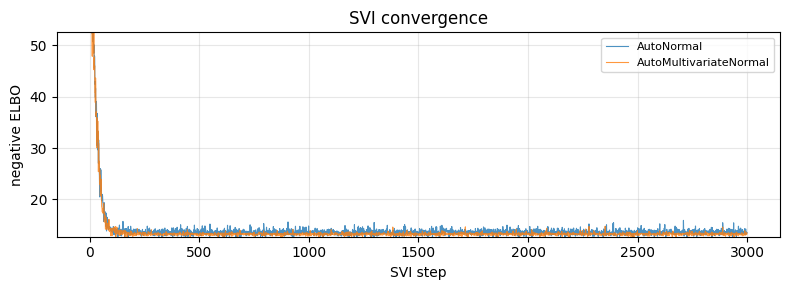

In [11]:
svi_samples = {}
svi_losses = {}
for guide_cls in (AutoNormal, AutoMultivariateNormal):
    guide = guide_cls(gp_model)
    svi = SVI(gp_model, guide, optax.adam(0.02), Trace_ELBO(num_particles=4))
    result = svi.run(jr.PRNGKey(3), 3000, times, y, progress_bar=False)
    svi_losses[guide_cls.__name__] = np.asarray(result.losses)
    svi_samples[guide_cls.__name__] = guide.sample_posterior(
        jr.PRNGKey(4), result.params, sample_shape=(2000,)
    )

fig, ax = plt.subplots(figsize=(8, 3))
for name, loss in svi_losses.items():
    ax.plot(loss, lw=0.8, alpha=0.8, label=name)
ax.set_ylim(np.percentile(np.concatenate(list(svi_losses.values())), [1, 99.5]))
ax.set_xlabel("SVI step")
ax.set_ylabel("negative ELBO")
ax.set_title("SVI convergence")
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 3.4 Comparing the posteriors

The scatter plots show $(\log \sigma^2, \log \ell)$ samples from each method, with the L-BFGS estimate marked; the table gives each method's posterior standard deviation of the three log-hyperparameters.

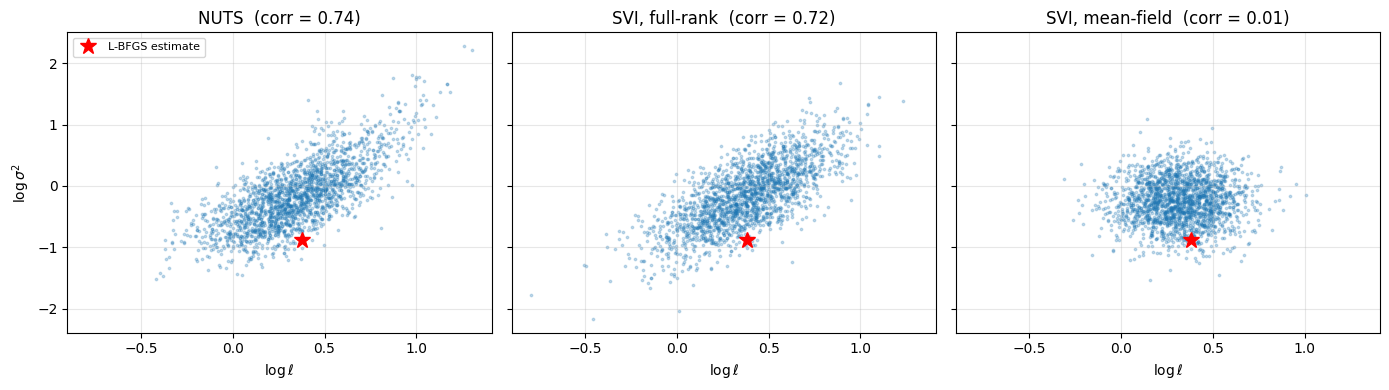

method              sd log var  sd log ell  sd log noise
NUTS                     0.529       0.266         0.219
SVI, full-rank           0.522       0.253         0.229
SVI, mean-field          0.359       0.184         0.229


In [12]:
methods = {
    "NUTS": nuts_samples,
    "SVI, full-rank": svi_samples["AutoMultivariateNormal"],
    "SVI, mean-field": svi_samples["AutoNormal"],
}
ml_point = (float(trained.log_variance), float(trained.log_lengthscale))

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharex=True, sharey=True)
for ax, (name, s) in zip(axes, methods.items(), strict=True):
    lv_s, ll_s = np.log(np.asarray(s["variance"])), np.log(np.asarray(s["lengthscale"]))
    ax.scatter(ll_s, lv_s, s=3, alpha=0.25, color="C0")
    ax.plot(ml_point[1], ml_point[0], "r*", ms=12, label="L-BFGS estimate")
    corr = np.corrcoef(lv_s, ll_s)[0, 1]
    ax.set_title(f"{name}  (corr = {corr:.2f})")
    ax.set_xlabel(r"$\log \ell$")
    ax.grid(alpha=0.3)
axes[0].set_ylabel(r"$\log \sigma^2$")
axes[0].legend(fontsize=8, loc="upper left")
fig.tight_layout()
plt.show()

print(f"{'method':<18}{'sd log var':>12}{'sd log ell':>12}{'sd log noise':>14}")
for name, s in methods.items():
    sds = [
        float(jnp.std(jnp.log(s[k]))) for k in ("variance", "lengthscale", "noise_var")
    ]
    print(f"{name:<18}{sds[0]:>12.3f}{sds[1]:>12.3f}{sds[2]:>14.3f}")

The NUTS posterior is a tilted ridge: larger variances go with longer lengthscales. Full-rank SVI reproduces both the tilt and the spread. Mean-field SVI cannot represent the correlation, so it fits an axis-aligned ellipse and understates the spread of $\log \sigma^2$ and $\log \ell$, the known behaviour of mean-field variational inference (Blei, Kucukelbir & McAuliffe, 2017). The noise variance is nearly uncorrelated with the other two, so all three methods agree on it. The L-BFGS estimate sits below the low-variance edge of the posterior cloud: it maximises the likelihood alone, while the posterior adds the priors and averages along the ridge, where larger variances paired with longer lengthscales fit almost as well.

Hyperparameter uncertainty propagates into predictions. Below, the NUTS posterior predictive averages the Kalman posterior over 200 posterior draws of $\boldsymbol{\theta}$ (one `jax.vmap` over `condition` and `predict`), and is compared with the plug-in band from the L-BFGS estimate.

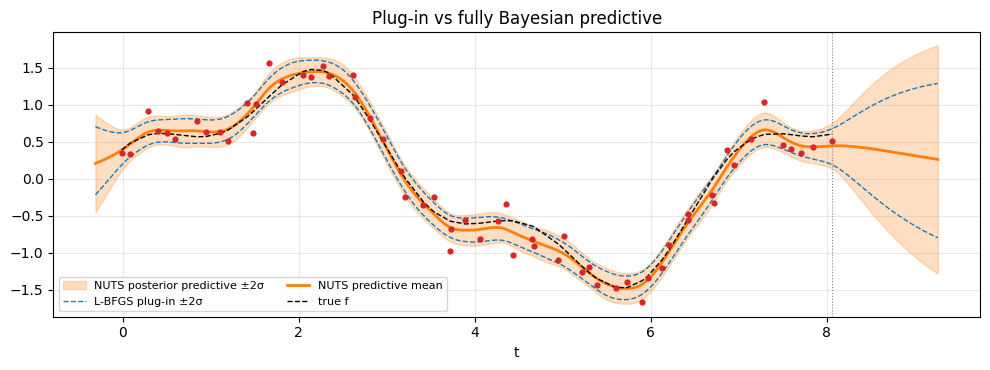

In [13]:
def predict_at(variance, lengthscale, noise_var):
    prior = MarkovGPPrior(
        MaternSDE(variance=variance, lengthscale=lengthscale, order=1), times
    )
    return prior.condition(y, noise_var).predict(t_star)


draws = jnp.arange(0, 2000, 10)
means, variances = jax.jit(jax.vmap(predict_at))(
    nuts_samples["variance"][draws],
    nuts_samples["lengthscale"][draws],
    nuts_samples["noise_var"][draws],
)
mix_mean = np.asarray(means.mean(0))
mix_sd = np.sqrt(np.asarray(variances.mean(0) + means.var(0)))

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.fill_between(
    t_star,
    mix_mean - 2 * mix_sd,
    mix_mean + 2 * mix_sd,
    color="C1",
    alpha=0.25,
    label="NUTS posterior predictive ±2σ",
)
ax.plot(
    t_star, m_star - 2 * sd_star, color="C0", lw=1, ls="--", label="L-BFGS plug-in ±2σ"
)
ax.plot(t_star, m_star + 2 * sd_star, color="C0", lw=1, ls="--")
ax.plot(t_star, mix_mean, color="C1", lw=2, label="NUTS predictive mean")
ax.plot(times, f_true, "k--", lw=1, label="true f")
ax.scatter(times, y, c="C3", s=12, zorder=3)
ax.axvline(times[-1], color="grey", ls=":", lw=0.8)
ax.set_xlabel("t")
ax.set_title("Plug-in vs fully Bayesian predictive")
ax.legend(fontsize=8, loc="lower left", ncol=2)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Inside the record the two bands nearly coincide: the data pin the function down wherever they are dense. Past the last observation the forecast band depends on $\sigma^2$ and $\ell$ directly, so averaging over their uncertainty widens it; that is where a plug-in estimate is most overconfident.

## 4. What a record can tell you about its hyperparameters

### 4.1 The variance–lengthscale ridge

The tilted ridge in §3.4 is not an accident of this data set. For a Matérn-$\nu$ process observed more and more densely on a fixed interval (*infill* sampling), $\sigma^2$ and $\ell$ cannot both be estimated consistently: only the combination $\sigma^2 / \ell^{2\nu}$ can (Zhang, 2004), which for Matern-3/2 is $\sigma^2 / \ell^3$. Sampling the same stretch more often sharpens that combination and nothing else. Only a longer record, more decorrelation lengths, separates $\sigma^2$ from $\ell$.

For a geoscience series the lengthscale is a **decorrelation time**: the memory of a sea-surface temperature anomaly, the persistence of a soil-moisture anomaly, the duration of a drought spell. Estimating it needs a record that spans many such times, which is often what a geophysical record does not have.

### 4.2 Record length, sampling density and gaps

To make this concrete we draw data from a known Matern-3/2 GP ($\sigma^2 = 1$, $\ell = 1$, noise variance $0.01$) and map the log marginal likelihood over $(\ell, \sigma^2)$ with the noise variance held at its true value, for four records:

1. a short record: $T = 10$ (ten decorrelation times), $N = 100$;
2. the same record sampled ten times more densely: $T = 10$, $N = 1000$ (infill, like moving from daily to hourly sampling);
3. a ten-times longer record at the original density: $T = 100$, $N = 1000$;
4. the long record with every other block of 10 time units missing, passed to the filter through `mask=` (like a sensor that is down every other season): $T = 100$, 501 observed.

The surfaces use `jax.vmap` over a grid and one `jax.jit`, so each costs a second or two.

record                             observed   ell where within 2 of max


T = 10, N = 100                         100             0.79 – 2.09


T = 10, N = 1000 (infill)              1000             0.91 – 2.00


T = 100, N = 1000                      1000             0.91 – 1.20


T = 100, half in gaps (501 obs)         501             0.91 – 1.32


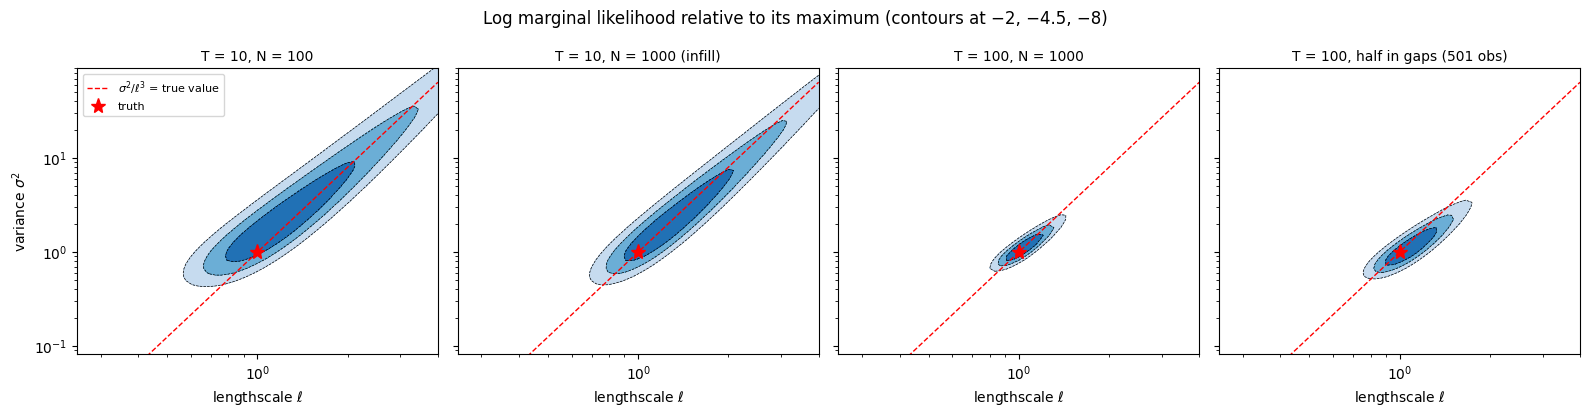

In [14]:
def simulate_gp(sde, t: jax.Array, key: jax.Array) -> jax.Array:
    """Draw f(t) from the SDE prior by forward simulation of its discrete-time model."""
    _F, _L, H, _Q_c, P_inf = sde.sde_params()
    A_seq, Q_seq = sde.discretise_sequence(jnp.diff(t))
    k0, k1 = jr.split(key)
    x0 = jnp.linalg.cholesky(P_inf) @ jr.normal(k0, (sde.state_dim,))
    L_seq = jnp.linalg.cholesky(Q_seq + 1e-12 * jnp.eye(sde.state_dim))
    eps = jr.normal(k1, (t.shape[0] - 1, sde.state_dim))

    def step(x, inputs):
        A_k, L_k, e_k = inputs
        x = A_k @ x + L_k @ e_k
        return x, x

    _, xs = jax.lax.scan(step, x0, (A_seq, L_seq, eps))
    return jnp.concatenate([x0[None], xs]) @ H[0]


truth = MaternSDE(variance=1.0, lengthscale=1.0, order=1)
true_noise = 0.01


def make_record(T: float, n: int, key: jax.Array, gaps: bool = False):
    t = jnp.linspace(0.0, T, n)
    yy = simulate_gp(truth, t, key) + jnp.sqrt(true_noise) * jr.normal(
        jr.fold_in(key, 1), (n,)
    )
    mask = (t % 20.0) < 10.0 if gaps else jnp.ones(n, dtype=bool)
    return t, yy, mask


log_var_grid = jnp.linspace(-2.5, 4.5, 71)
log_ell_grid = jnp.linspace(jnp.log(0.25), jnp.log(4.0), 61)


@jax.jit
def likelihood_surface(t, yy, mask):
    def one(log_var, log_ell):
        prior = MarkovGPPrior(MaternSDE(jnp.exp(log_var), jnp.exp(log_ell), order=1), t)
        return prior.log_marginal(yy, jnp.asarray(true_noise), mask=mask)

    return jax.vmap(lambda a: jax.vmap(lambda b: one(a, b))(log_ell_grid))(log_var_grid)


key = jr.PRNGKey(11)
records = {
    "T = 10, N = 100": make_record(10.0, 100, key),
    "T = 10, N = 1000 (infill)": make_record(10.0, 1000, key),
    "T = 100, N = 1000": make_record(100.0, 1000, key),
    "T = 100, half in gaps (501 obs)": make_record(100.0, 1000, key, gaps=True),
}

ell_axis = np.exp(np.asarray(log_ell_grid))
var_axis = np.exp(np.asarray(log_var_grid))
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), sharey=True)
print(f"{'record':<34}{'observed':>9}{'ell where within 2 of max':>28}")
for ax, (name, (t, yy, mask)) in zip(axes, records.items(), strict=True):
    surf = np.asarray(likelihood_surface(t, yy, mask))
    surf = surf - surf.max()
    ax.contourf(
        ell_axis,
        var_axis,
        surf,
        levels=[-8, -4.5, -2, 0],
        colors=["#c6dbef", "#6baed6", "#2171b5"],
    )
    ax.contour(
        ell_axis, var_axis, surf, levels=[-8, -4.5, -2], colors="k", linewidths=0.5
    )
    ax.plot(
        ell_axis, ell_axis**3, "r--", lw=1, label=r"$\sigma^2 / \ell^3$ = true value"
    )
    ax.plot(1.0, 1.0, "r*", ms=11, label="truth")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlim(ell_axis[0], ell_axis[-1])
    ax.set_ylim(var_axis[0], var_axis[-1])
    ax.set_xlabel(r"lengthscale $\ell$")
    ax.set_title(name, fontsize=10)
    inside = (surf > -2.0).any(axis=0)
    print(
        f"{name:<34}{int(mask.sum()):>9}{ell_axis[inside].min():>17.2f} – {ell_axis[inside].max():.2f}"
    )
axes[0].set_ylabel(r"variance $\sigma^2$")
axes[0].legend(fontsize=8, loc="upper left")
fig.suptitle(
    "Log marginal likelihood relative to its maximum (contours at −2, −4.5, −8)"
)
fig.tight_layout()
plt.show()

Three things stand out.

- **Every surface is a ridge along $\sigma^2 / \ell^3 = \text{const}$**, the red line through the truth, as Zhang's result predicts. Along the ridge the likelihood barely changes, so $\sigma^2$ and $\ell$ separately are poorly determined even when their combination is sharp.
- **Infill does not help with the lengthscale.** Ten times more observations on the same interval make the ridge thinner but not shorter: the range of $\ell$ within two log-units of the maximum barely moves. Sampling the same record ten times more often does not reveal a decorrelation time that the record's length cannot.
- **Record length does.** The ten-times longer record shrinks the ridge to a small ellipse around the truth. Even with half of it missing, its 501 observations constrain $\ell$ far better than the 1000 observations packed into the short record, because what informs $\ell$ is the number of decorrelation times observed, not the number of points. Masking the gaps keeps every observed step and adds no imputed ones.

### 4.3 Practical guidance for geoscience records

1. **Count decorrelation times, not points.** Compare the record length with the plausible range of $\ell$ before trusting a fitted lengthscale. In the experiment above, ten decorrelation times left every $\ell$ from about 0.8 to 2.1 within two log-units of the maximum, a factor of 2.6.
2. **Report what is identified.** For a Matérn-$\nu$ fit, $\sigma^2 / \ell^{2\nu}$ is well determined and $\sigma^2$ and $\ell$ separately may not be; interpret them together, and prefer predictions and their uncertainty over individual hyperparameter values.
3. **Use priors that encode the record.** Keep $\ell$ between the sampling interval and the record length, as the inverse-gamma prior in §3.1 does. Penalised-complexity priors for the Matérn range and variance (Fuglstad et al., 2019) are a principled default; pyrox-lgm implements them for its latent Gaussian models.
4. **Propagate hyperparameter uncertainty where it matters.** Plug-in estimates are fine for interpolation inside a dense record and overconfident for forecasts and long gaps. Use NUTS when the posterior is small, as here; use full-rank rather than mean-field VI when it is not.
5. **Handle gaps with `mask=`.** Missing seasons or outages need no imputation, and as §4.2 shows, a long record with gaps can be worth more than a short complete one.

## Summary

- `MarkovGPPrior.log_marginal` is differentiable and linear in $N$, so type-II maximum likelihood (L-BFGS), NUTS and SVI over the kernel hyperparameters are all cheap; `markov_gp_factor` puts it in a NumPyro model with the latent function integrated out.
- The hyperparameter posterior is a correlated ridge in $(\log \sigma^2, \log \ell)$. NUTS and full-rank SVI capture it; mean-field SVI understates its spread.
- Only $\sigma^2 / \ell^{2\nu}$ is fixed by dense sampling of a fixed record; separating $\sigma^2$ from $\ell$ takes a record many decorrelation times long, and a long record with gaps beats a short dense one.

For non-Gaussian likelihoods, plug a `MarkovGPPrior` into one of the strategies in the companion non-Gaussian Markov GP notebook; `LaplaceMarkovInference`'s `log_marginal_approx` approximates the evidence and can play the role of the loss.

**References.**

1. Blei, D. M., Kucukelbir, A. & McAuliffe, J. D. (2017). *Variational inference: a review for statisticians.* JASA 112(518), 859–877.
2. Fuglstad, G.-A., Simpson, D., Lindgren, F. & Rue, H. (2019). *Constructing priors that penalize the complexity of Gaussian random fields.* JASA 114(525), 445–452.
3. Hoffman, M. D. & Gelman, A. (2014). *The No-U-Turn sampler: adaptively setting path lengths in Hamiltonian Monte Carlo.* JMLR 15, 1593–1623.
4. Zhang, H. (2004). *Inconsistent estimation and asymptotically equal interpolations in model-based geostatistics.* JASA 99(465), 250–261.